# TD 13 : Échantillon et échantillonnage — Correction

<div class="alert alert-info">

## Objectifs

- Comprendre la différence entre une **population** et un **échantillon**
- Comprendre ce qu'est un échantillon **représentatif**, et les conséquences d'un échantillon non-représentatif
- Connaître les principales **méthodes d'échantillonnage** (aléatoire simple, stratifié, systématique, en grappes)
- Illustrer ces notions avec R, et comprendre leur lien avec les autres notions statistiques vues en TD (intervalles de confiance, tests de comparaison, tests du chi²...)

</div>

## 1. Population et échantillon

En statistique, la **population** désigne l'ensemble complet des individus (patients, vaccins, cellules...) sur lequel on souhaite tirer des conclusions. Il est en général impossible, trop coûteux ou trop long d'observer l'intégralité de la population (penser à l'ensemble des patients atteints d'une maladie dans le monde).

On étudie donc un sous-ensemble de la population, appelé **échantillon**, que l'on observe réellement, et à partir duquel on va essayer d'estimer les caractéristiques de la population (moyenne, proportion, variance...). L'opération qui consiste à sélectionner cet échantillon dans la population s'appelle l'**échantillonnage**.

<div class="alert alert-warning">

**Vocabulaire**

- **Population** : ensemble de tous les individus concernés par l'étude (souvent notée de taille $N$, parfois infinie ou inconnue)
- **Échantillon** : sous-ensemble observé de la population (de taille $n$, avec $n \leq N$)
- **Paramètre** : caractéristique numérique de la *population* (ex. moyenne $\mu$, proportion $p$) — en général inconnue
- **Statistique (ou estimation)** : caractéristique numérique calculée sur l'*échantillon* (ex. moyenne $\bar{x}$, proportion observée $\hat{p}$) — utilisée pour estimer le paramètre

</div>

C'est exactement la logique déjà rencontrée dans le TD sur les intervalles de confiance : on ne peut jamais connaître la vraie moyenne $\mu$ d'une population, on ne peut qu'estimer $\mu$ par la moyenne $\bar{x}$ d'un échantillon, avec une incertitude associée.

## 2. Illustration : simuler une population et des échantillons

Pour bien comprendre la différence entre population et échantillon, on va simuler une population *entière* et fictive de 10 000 patients, dont on connaît (puisqu'on l'a créée nous-même) la vraie moyenne d'âge. En pratique, cette population est quasiment toujours inconnue : ici c'est une expérience pédagogique.

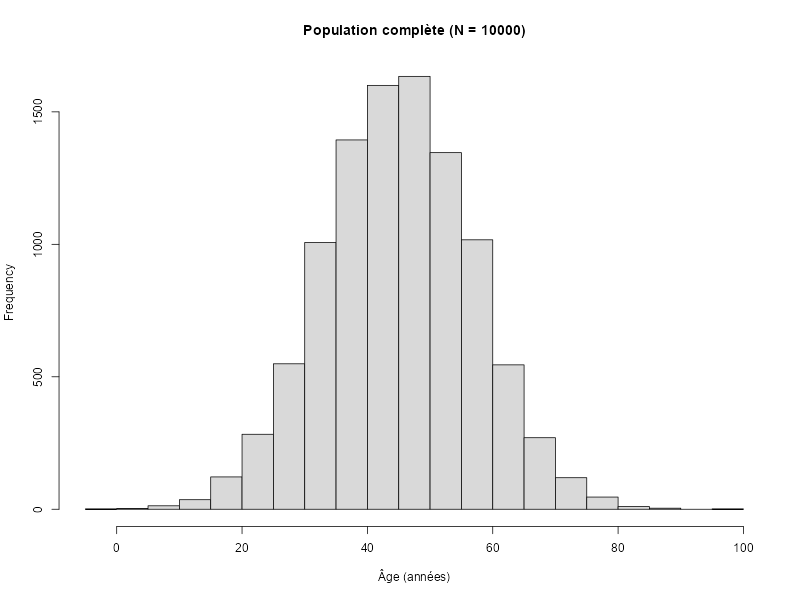

In [1]:
set.seed(7421)

# Population fictive de 10 000 patients (âge en années)
N <- 10000
population <- rnorm(N, mean = 45, sd = 12)

# "Vraie" moyenne de la population (inconnue en pratique !)
mean(population)

hist(population, main = "Population complète (N = 10000)",
     xlab = "Âge (années)", col = "grey85")

### 2.1 Variabilité d'échantillonnage

Si on tire plusieurs échantillons différents dans la même population, la moyenne calculée sur chaque échantillon varie : c'est la **variabilité d'échantillonnage**, déjà illustrée dans le TD sur les intervalles de confiance avec l'exemple des vaccins non-conformes.

In [2]:
# On tire 5 échantillons aléatoires de taille n = 30 dans la population
n <- 30
moyennes_echantillons <- replicate(5, {
  echantillon <- sample(population, size = n)
  mean(echantillon)
})

print(moyennes_echantillons)

# Comparaison à la vraie moyenne de la population
print(mean(population))

[1] 42.61321 46.47332 44.21627 47.51062 46.04674
[1] 44.9562


On observe que chaque échantillon donne une moyenne légèrement différente, et différente de la vraie moyenne de la population (ici $\approx 45$ ans). C'est cette variabilité qui justifie de ne jamais se contenter d'une estimation ponctuelle (une seule moyenne) et de toujours l'accompagner d'un **intervalle de confiance**, comme vu précédemment.

<div class="alert alert-success">

### ✏️ Exercice 1 : taille de l'échantillon et variabilité — Correction

1. Reprenez le code ci-dessus et tirez maintenant 5 échantillons de taille `n = 5` (au lieu de `n = 30`) dans `population`. Affichez les 5 moyennes obtenues.
2. Tirez ensuite 5 échantillons de taille `n = 500`. Affichez les 5 moyennes obtenues.
3. Comparez la dispersion des moyennes obtenues dans les trois cas (`n = 5`, `n = 30`, `n = 500`). Que se passe-t-il quand la taille de l'échantillon augmente ?
4. *(Pour aller plus loin)* Utilisez `replicate()` pour tirer 1000 échantillons de chaque taille, et calculez l'écart-type des 1000 moyennes obtenues pour chaque taille avec `sd()`. Commentez.

</div>

In [3]:
# 1. et 2. Échantillons de taille n = 5 et n = 500
moyennes_n5 <- replicate(5, mean(sample(population, size = 5)))
moyennes_n500 <- replicate(5, mean(sample(population, size = 500)))

print(moyennes_n5)
print(moyennes_n500)

[1] 46.09213 53.71499 50.98821 45.46350 45.39616
[1] 45.62981 45.10172 44.82434 44.24905 45.14398


In [4]:
# 4. Variabilité des moyennes sur 1000 répétitions, pour les 3 tailles d'échantillon
sd_n5 <- sd(replicate(1000, mean(sample(population, size = 5))))
sd_n30 <- sd(replicate(1000, mean(sample(population, size = 30))))
sd_n500 <- sd(replicate(1000, mean(sample(population, size = 500))))

print(sd_n5)
print(sd_n30)
print(sd_n500)

[1] 5.241926
[1] 2.195076
[1] 0.5111936


**Commentaire** :

- Avec `n = 5`, les 5 moyennes obtenues sont très dispersées (certaines s'éloignent nettement de 45 ans), alors qu'avec `n = 500`, les 5 moyennes sont toutes très proches de la vraie moyenne de la population.
- Les écarts-types calculés sur 1000 répétitions le confirment numériquement : la variabilité d'échantillonnage diminue fortement quand la taille de l'échantillon augmente (environ 5.2 pour n=5, 2.2 pour n=30, 0.5 pour n=500 dans cette simulation). Plus l'échantillon est grand, plus l'estimation de la moyenne est précise — c'est le principe qui sous-tend la réduction de la largeur des intervalles de confiance quand $n$ augmente (TD3).

## 3. Représentativité d'un échantillon

Un échantillon est dit **représentatif** lorsque sa composition reflète correctement celle de la population dont il est issu, pour les caractéristiques qui nous intéressent (âge, sexe, gravité de la maladie...). Un échantillon représentatif permet de généraliser les résultats observés à l'ensemble de la population.

À l'inverse, un échantillon est **non-représentatif** (ou biaisé) lorsque certains sous-groupes de la population sont sur- ou sous-représentés par rapport à leur proportion réelle. Les estimations obtenues sur un échantillon non-représentatif sont alors **biaisées** : même avec un échantillon de grande taille, elles ne convergeront pas vers la vraie valeur du paramètre de population.

<div class="alert alert-danger">

**Attention** : augmenter la taille de l'échantillon réduit la variabilité d'échantillonnage (l'estimation devient plus précise, l'intervalle de confiance plus étroit), mais ne corrige en rien un biais de représentativité. Un grand échantillon mal échantillonné reste un échantillon biaisé.

</div>

### 3.1 Exemple : échantillon non-représentatif

Reprenons notre population fictive de patients, mais supposons maintenant qu'elle contient aussi une variable de sexe, et que les femmes ont en moyenne un âge différent des hommes. Si notre méthode de recrutement favorise un sexe par rapport à l'autre (par exemple un recrutement en consultation de gynécologie), l'échantillon obtenu sera non-représentatif de la population pour la variable âge.

In [5]:
# Population avec sexe et âge liés (femmes en moyenne plus âgées ici, exemple fictif)
sexe <- sample(c("F", "H"), size = N, replace = TRUE)
age <- ifelse(sexe == "F", rnorm(N, mean = 50, sd = 10), rnorm(N, mean = 40, sd = 10))
population2 <- data.frame(sexe = sexe, age = age)

# Vraie proportion de femmes et vraie moyenne d'âge dans la population
print(prop.table(table(population2$sexe)))
print(mean(population2$age))

# Échantillon ALEATOIRE : tirage au hasard dans toute la population
echantillon_alea <- population2[sample(1:N, size = 100), ]
print(prop.table(table(echantillon_alea$sexe)))
print(mean(echantillon_alea$age))

# Échantillon BIAISE : recrutement qui sur-représente les femmes (ex : consultation ciblée)
index_biais <- c(sample(which(population2$sexe == "F"), size = 80),
                  sample(which(population2$sexe == "H"), size = 20))
echantillon_biais <- population2[index_biais, ]
print(prop.table(table(echantillon_biais$sexe)))
print(mean(echantillon_biais$age))


     F      H 
0.5017 0.4983 
[1] 45.00575

   F    H 
0.49 0.51 
[1] 42.96479

  F   H 
0.8 0.2 
[1] 49.47075


**Interprétation** :

- Dans la population, la proportion de femmes est d'environ 50 %, et l'âge moyen est d'environ 45 ans.
- L'échantillon aléatoire retrouve une proportion de femmes proche de 50 % et un âge moyen proche de la vraie valeur : c'est un échantillon représentatif (aux fluctuations d'échantillonnage près).
- L'échantillon biaisé sur-représente très largement les femmes (80 % contre 50 % dans la population). Comme les femmes sont en moyenne plus âgées dans cette population fictive, l'âge moyen estimé sur cet échantillon est biaisé vers le haut, et ce **quel que soit le nombre de patients recrutés** dans ces mêmes proportions.

Visualisons la distribution des âges par sexe dans la population pour mieux comprendre d'où vient ce biais.

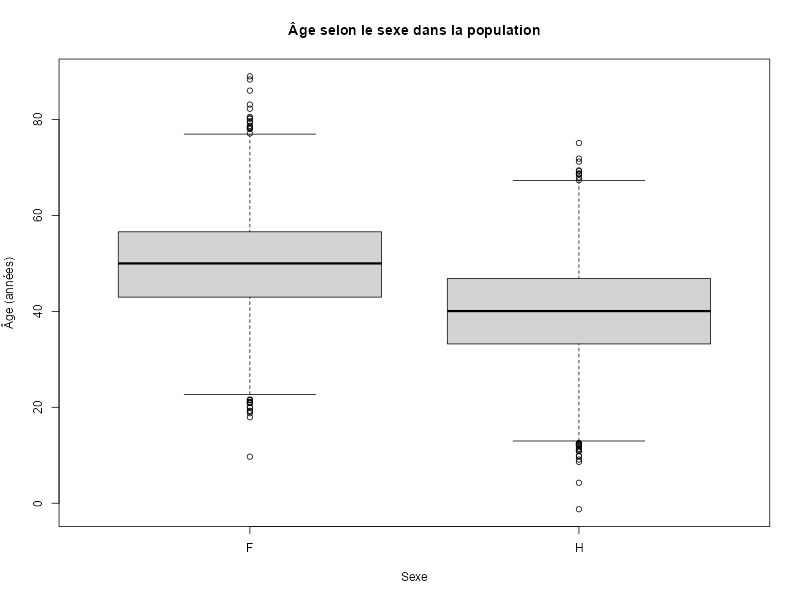

In [6]:
boxplot(age ~ sexe, data = population2,
        main = "Âge selon le sexe dans la population",
        xlab = "Sexe", ylab = "Âge (années)")

<div class="alert alert-success">

### ✏️ Exercice 2 : construire un échantillon biaisé — Correction

En vous inspirant du code ci-dessus (variable `population2`) :

1. Construisez un échantillon `echantillon_biais2` de 100 patients qui sur-représente cette fois les **hommes** (par exemple 90 hommes et 10 femmes), en utilisant `sample()` et `which()`.
2. Calculez la proportion de femmes et la moyenne d'âge de cet échantillon.
3. Dans quel sens est biaisée cette moyenne par rapport à la vraie moyenne de la population (`mean(population2$age)`) ? Expliquez pourquoi, à l'aide du boxplot ci-dessus.
4. Imaginez un contexte clinique réel (type de recrutement, de service, de lieu...) qui pourrait produire ce genre de biais de sur-représentation des hommes.

</div>

In [7]:
# 1. et 2. Échantillon sur-représentant les hommes
index_biais2 <- c(sample(which(population2$sexe == "H"), size = 90),
                   sample(which(population2$sexe == "F"), size = 10))
echantillon_biais2 <- population2[index_biais2, ]

print(prop.table(table(echantillon_biais2$sexe)))
print(mean(echantillon_biais2$age))

# Comparaison à la vraie moyenne de la population
print(mean(population2$age))


  F   H 
0.1 0.9 
[1] 41.19047
[1] 45.00575


**Réponses 3 et 4** :

3. La moyenne d'âge estimée (≈ 41.2 ans) est biaisée **vers le bas** par rapport à la vraie moyenne de la population (≈ 45 ans). Le boxplot montre que les hommes ont un âge médian plus faible que les femmes dans cette population ; en sur-représentant les hommes (90 % au lieu de 50 %), on tire mécaniquement la moyenne de l'échantillon vers l'âge moyen des hommes.
4. Exemple de contexte réel : un recrutement de patients dans un service d'urologie, de cardiologie interventionnelle (historiquement plus fréquenté par des hommes), ou une étude militaire, pourrait sur-représenter les hommes par rapport à la population générale. De façon plus générale, tout recrutement dans un lieu ou une filière de soins fréquentée différemment selon le sexe produit ce type de biais.

## 4. Méthodes d'échantillonnage

Le choix de la **méthode d'échantillonnage** (ou **stratégie d'échantillonnage**) conditionne la représentativité de l'échantillon obtenu. On distingue principalement :

<div class="alert alert-warning">

**Principales méthodes d'échantillonnage probabilistes**

- **Échantillonnage aléatoire simple** : chaque individu de la population a la même probabilité d'être sélectionné, indépendamment des autres (ex. tirage au sort dans la liste complète des patients).
- **Échantillonnage stratifié** : on découpe d'abord la population en sous-groupes homogènes (*strates*, ex. par sexe, par tranche d'âge, par centre hospitalier), puis on tire un échantillon aléatoire simple **dans chaque strate**, en général proportionnellement à la taille de la strate dans la population. Cela garantit la représentativité sur la variable de stratification.
- **Échantillonnage systématique** : on trie la population puis on sélectionne un individu tous les $k$ individus (ex. 1 patient sur 10 dans un registre), à partir d'un point de départ aléatoire.
- **Échantillonnage en grappes (*cluster sampling*)** : on découpe la population en groupes (*grappes*, ex. hôpitaux, villages), on tire aléatoirement quelques grappes entières, puis on inclut tous les individus (ou un sous-échantillon) de ces grappes. Pratique quand la population est dispersée géographiquement, mais souvent moins précis car les individus d'une même grappe se ressemblent.

</div>

Il existe aussi des méthodes **non-probabilistes** (échantillonnage de convenance, volontariat, quotas...), plus faciles et moins coûteuses à mettre en œuvre, mais pour lesquelles le risque de biais de représentativité est généralement plus élevé car la probabilité de sélection de chaque individu n'est pas connue ni contrôlée.

### 4.1 Illustration : échantillonnage stratifié vs. aléatoire simple

Reprenons notre population `population2` (sexe, âge) et comparons un échantillonnage aléatoire simple à un échantillonnage stratifié par sexe, à taille d'échantillon égale (n = 100).

In [8]:
# Échantillonnage aléatoire simple (n = 100)
echantillon_simple <- population2[sample(1:N, size = 100), ]

# Échantillonnage stratifié par sexe, proportionnel (ici ~50 F / 50 H car la
# population est d'environ 50% de chaque sexe)
n_F <- 50
n_H <- 50
echantillon_stratifie <- rbind(
  population2[sample(which(population2$sexe == "F"), size = n_F), ],
  population2[sample(which(population2$sexe == "H"), size = n_H), ]
)

# Comparaison des proportions de sexe obtenues
print(prop.table(table(echantillon_simple$sexe)))
print(prop.table(table(echantillon_stratifie$sexe)))

# Comparaison des moyennes d'âge obtenues, à comparer à la vraie moyenne (45.04)
print(mean(echantillon_simple$age))
print(mean(echantillon_stratifie$age))


   F    H 
0.56 0.44 

  F   H 
0.5 0.5 
[1] 45.41571
[1] 46.16057


Sur un seul tirage, les deux méthodes donnent des estimations proches de la vraie moyenne (≈ 45.0 ans), car la population est ici parfaitement équilibrée entre les sexes. L'avantage de la stratification apparaît surtout en termes de **variabilité d'échantillonnage** : en forçant la proportion de chaque strate, on supprime la part de variabilité due au hasard sur la composition de l'échantillon. Vérifions cela en répétant l'échantillonnage un grand nombre de fois.

[1] 1.092879
[1] 0.9968565


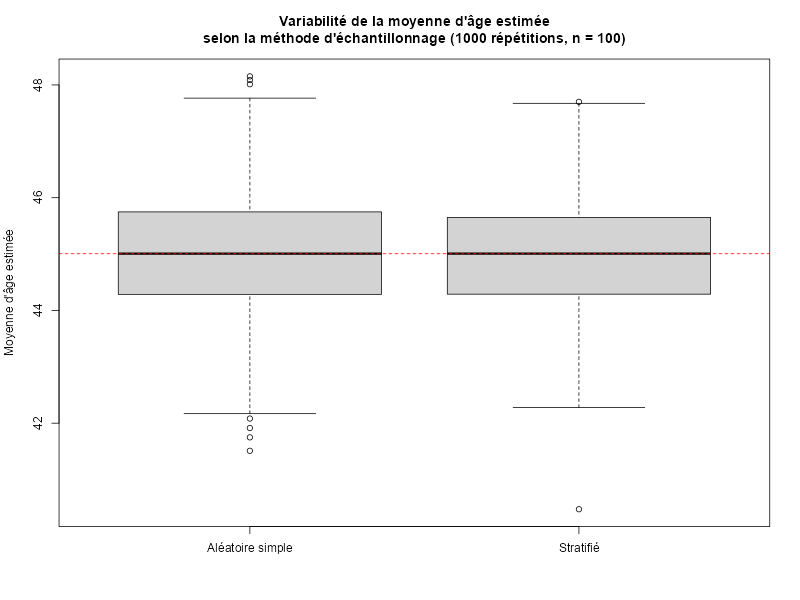

In [9]:
tirer_moyenne_simple <- function() {
  ech <- population2[sample(1:N, size = 100), ]
  mean(ech$age)
}

tirer_moyenne_stratifiee <- function() {
  ech <- rbind(
    population2[sample(which(population2$sexe == "F"), size = 50), ],
    population2[sample(which(population2$sexe == "H"), size = 50), ]
  )
  mean(ech$age)
}

moyennes_simple <- replicate(1000, tirer_moyenne_simple())
moyennes_stratifiee <- replicate(1000, tirer_moyenne_stratifiee())

# Écart-type des moyennes obtenues sur les 1000 répétitions : mesure de la
# variabilité d'échantillonnage pour chaque méthode
print(sd(moyennes_simple))
print(sd(moyennes_stratifiee))

boxplot(moyennes_simple, moyennes_stratifiee,
        names = c("Aléatoire simple", "Stratifié"),
        main = "Variabilité de la moyenne d'âge estimée\nselon la méthode d'échantillonnage (1000 répétitions, n = 100)",
        ylab = "Moyenne d'âge estimée")
abline(h = mean(population2$age), col = "red", lty = 2)

Ici, les deux méthodes donnent des écarts-types très proches (le gain de précision de la stratification est modeste), car la population est déjà équilibrée à 50/50 entre les sexes. Le bénéfice de la stratification serait beaucoup plus net si la strate (sexe) était rare dans la population (ex. 10 % de femmes) : l'échantillonnage aléatoire simple risquerait alors, par malchance, d'en tirer trop peu ou trop, alors que la stratification garantit toujours la bonne proportion.

<div class="alert alert-success">

### ✏️ Exercice 3 : un échantillonnage stratifié non-proportionnel — Correction

Reprenez le code `tirer_moyenne_stratifiee()` ci-dessus.

1. Créez une population déséquilibrée `population3` où les femmes ne représentent que 10 % des patients (par exemple avec `sample(c("F", "H"), size = N, replace = TRUE, prob = c(0.1, 0.9))`), en gardant les mêmes moyennes d'âge par sexe (50 ans pour les femmes, 40 ans pour les hommes).
2. Calculez la vraie moyenne d'âge de `population3`.
3. Adaptez les fonctions `tirer_moyenne_simple()` et `tirer_moyenne_stratifiee()` pour qu'elles utilisent `population3`, avec un échantillon stratifié proportionnel (10 femmes, 90 hommes pour n = 100).
4. Répétez 1000 fois chaque méthode, calculez l'écart-type des 1000 moyennes obtenues pour les deux méthodes, et comparez-les.
5. Le gain de précision de la stratification est-il plus important ou moins important que dans l'exemple du cours (population équilibrée à 50/50) ? Pourquoi, intuitivement ?

</div>

In [10]:
# 1. et 2. Population déséquilibrée (10% femmes / 90% hommes)
sexe3 <- sample(c("F", "H"), size = N, replace = TRUE, prob = c(0.1, 0.9))
age3 <- ifelse(sexe3 == "F", rnorm(N, mean = 50, sd = 10), rnorm(N, mean = 40, sd = 10))
population3 <- data.frame(sexe = sexe3, age = age3)

print(prop.table(table(population3$sexe)))
print(mean(population3$age))


     F      H 
0.1007 0.8993 
[1] 40.97528


[1] 1.025869
[1] 0.9970772


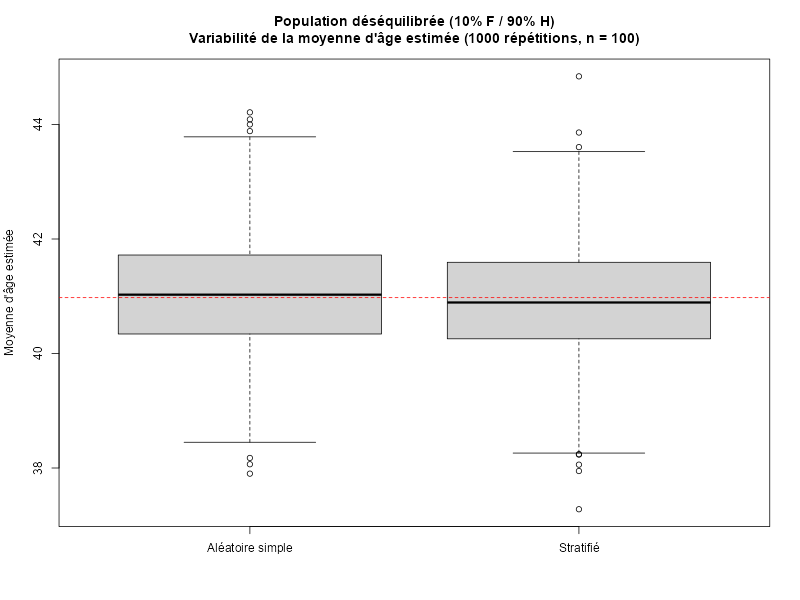

In [11]:
# 3. et 4. Fonctions adaptées à population3, échantillonnage stratifié proportionnel (10 F / 90 H)
tirer_moyenne_simple3 <- function() {
  ech <- population3[sample(1:N, size = 100), ]
  mean(ech$age)
}

tirer_moyenne_stratifiee3 <- function() {
  ech <- rbind(
    population3[sample(which(population3$sexe == "F"), size = 10), ],
    population3[sample(which(population3$sexe == "H"), size = 90), ]
  )
  mean(ech$age)
}

moyennes_simple3 <- replicate(1000, tirer_moyenne_simple3())
moyennes_stratifiee3 <- replicate(1000, tirer_moyenne_stratifiee3())

print(sd(moyennes_simple3))
print(sd(moyennes_stratifiee3))

boxplot(moyennes_simple3, moyennes_stratifiee3,
        names = c("Aléatoire simple", "Stratifié"),
        main = "Population déséquilibrée (10% F / 90% H)\nVariabilité de la moyenne d'âge estimée (1000 répétitions, n = 100)",
        ylab = "Moyenne d'âge estimée")
abline(h = mean(population3$age), col = "red", lty = 2)

**Réponse 5** :

Contrairement à l'intuition qu'on pourrait avoir, le gain de précision de la stratification reste ici modeste (écart-type ≈ 1.03 pour l'aléatoire simple contre ≈ 1.00 pour le stratifié), et donc proche de ce qu'on observait avec une population équilibrée à 50/50. 

Explication : même si la strate "femmes" est rare (10 %), la taille de l'échantillon (n = 100) reste suffisamment grande pour que la proportion de femmes tirée au hasard dans l'échantillon aléatoire simple varie assez peu autour de 10 % (écart-type binomial théorique $\sqrt{0{,}1 \times 0{,}9 / 100} \approx 3\%$). Le gain de la stratification serait plus visible avec un échantillon de plus petite taille (où le risque de tirer 0 ou très peu de femmes par hasard devient non-négligeable), ou avec une strate encore plus rare (ex. 1 % de la population). Cet exercice illustre que le bénéfice théorique de la stratification dépend du contexte (taille de l'échantillon, rareté de la strate) et doit être vérifié plutôt que supposé automatiquement important.

## 5. Synthèse et lien avec les autres notions du cours

```mermaid
flowchart LR
    A[Population] -- échantillonnage --> B[Échantillon]
    B -- statistique descriptive --> C["Estimation ponctuelle (moyenne, proportion...)"]
    C -- variabilité d'échantillonnage --> D["Intervalle de confiance (TD3)"]
    D --> E["Tests d'hypothèses : comparaison de moyennes (TD4-TD8),\ntests du chi² (TD10), tests d'ajustement (TD9)"]
```

- Tout ce que l'on calcule dans les autres TD (moyenne, écart-type, intervalle de confiance, tests statistiques) est calculé **sur un échantillon**, et sert à faire des inférences sur la **population** dont il est issu.
- La **représentativité** de l'échantillon est une condition nécessaire, mais rarement discutée explicitement, pour que ces inférences soient valides : un test statistique parfaitement mené sur un échantillon biaisé donnera une conclusion statistiquement correcte... sur un échantillon qui ne représente pas la population d'intérêt.
- La **variabilité d'échantillonnage** est à l'origine de la nécessité des intervalles de confiance (TD3) : deux échantillons différents, même tirés selon la même méthode, donnent des estimations différentes.
- La **taille de l'échantillon** $n$ influence la précision de l'estimation (intervalles de confiance plus étroits, tests plus puissants), mais seule la **méthode d'échantillonnage** influence le biais de représentativité : un échantillon de grande taille mais mal échantillonné reste trompeur.

<div class="alert alert-info">

**À retenir**

- Population $\neq$ échantillon ; paramètre $\neq$ statistique/estimation.
- Un échantillon représentatif reflète la composition de la population ; un échantillon biaisé produit des estimations biaisées, quelle que soit sa taille.
- Le choix de la méthode d'échantillonnage (aléatoire simple, stratifié, systématique, en grappes...) doit être adapté au contexte et discuté **avant** de récolter les données, pas après.

</div>

<div class="alert alert-success">

### ✏️ Exercice 4 : synthèse (sans code) — Correction

Un laboratoire souhaite estimer la proportion de patients souffrant d'hypertension artérielle dans une région. Pour cela, l'équipe recrute 2000 patients en demandant à des volontaires de répondre à un questionnaire en ligne.

**1. Population et échantillon**

La population d'intérêt est l'ensemble des habitants de la région (ou des patients de la région, selon la définition exacte de l'étude). L'échantillon est constitué des 2000 volontaires ayant répondu au questionnaire en ligne.

**2. Risques de non-représentativité**

- **Biais d'auto-sélection (volontariat)** : les personnes qui choisissent de répondre spontanément à un questionnaire sur l'hypertension ne sont pas un tirage aléatoire de la population ; elles sont probablement plus concernées ou plus sensibilisées au sujet (par exemple déjà diagnostiquées, ou au contraire très soucieuses de leur santé), ce qui peut surestimer ou sous-estimer la proportion réelle de la maladie.
- **Biais d'accès au questionnaire en ligne** : un questionnaire en ligne exclut structurellement les personnes sans accès à internet ou peu à l'aise avec le numérique, qui sont souvent des personnes plus âgées — justement la population la plus à risque d'hypertension. Cela peut biaiser l'échantillon vers une population plus jeune et en meilleure santé numérique.

**3. Augmenter la taille de l'échantillon est-il une solution ?**

Non. Passer de 2000 à 20 000 volontaires réduira la variabilité d'échantillonnage (l'estimation de la proportion sera plus précise, l'intervalle de confiance plus étroit), mais ne corrige en rien les deux biais identifiés ci-dessus : les 20 000 volontaires resteraient des volontaires, avec les mêmes caractéristiques de sur- ou sous-représentation. Le biais de représentativité persiste quelle que soit la taille de l'échantillon (comme vu en section 3).

**4. Méthode d'échantillonnage plus adaptée**

Un **échantillonnage aléatoire simple** (ou mieux, **stratifié** par âge et par zone géographique) tiré directement dans une base de sondage représentative de la population (ex. listes de patients de médecins généralistes, registre d'assurance maladie, recensement), avec un contact actif des personnes sélectionnées (par courrier ou téléphone plutôt que par volontariat en ligne), permettrait de garantir que chaque individu de la population ait une probabilité connue d'être inclus, et donc d'obtenir un échantillon représentatif en âge et en zone géographique — deux facteurs probablement liés à la prévalence de l'hypertension.

</div>